In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [ ]:

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"

columns = [
    "Customer_Segment",
    "Alcohol",
    "Malic_Acid",
    "Ash",
    "Ash_Alcanity",
    "Magnesium",
    "Total_Phenols",
    "Flavanoids",
    "Nonflavanoid_Phenols",
    "Proanthocyanins",
    "Color_Intensity",
    "Hue",
    "OD280",
    "Proline"
]

df = pd.read_csv(url, header=None, names=columns)


In [ ]:

print(df.head())


   Customer_Segment  Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  \
0                 1    14.23        1.71  2.43          15.6        127   
1                 1    13.20        1.78  2.14          11.2        100   
2                 1    13.16        2.36  2.67          18.6        101   
3                 1    14.37        1.95  2.50          16.8        113   
4                 1    13.24        2.59  2.87          21.0        118   

   Total_Phenols  Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  \
0           2.80        3.06                  0.28             2.29   
1           2.65        2.76                  0.26             1.28   
2           2.80        3.24                  0.30             2.81   
3           3.85        3.49                  0.24             2.18   
4           2.80        2.69                  0.39             1.82   

   Color_Intensity   Hue  OD280  Proline  
0             5.64  1.04   3.92     1065  
1             4.38  1.05   3.40     

In [ ]:

X = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]


In [ ]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:

pca = PCA()
X_pca = pca.fit_transform(X_scaled)


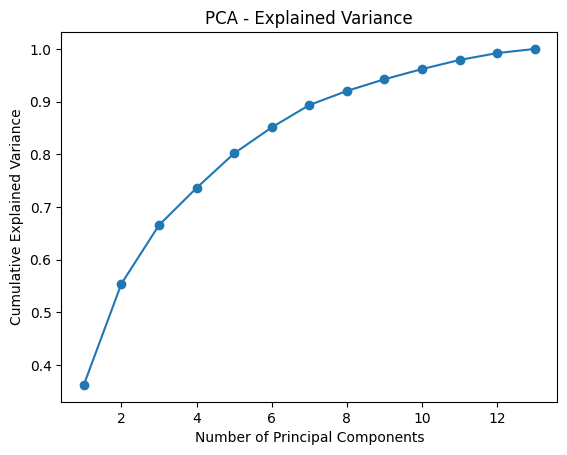

In [ ]:

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_.cumsum(),
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.show()


In [ ]:

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X_scaled)


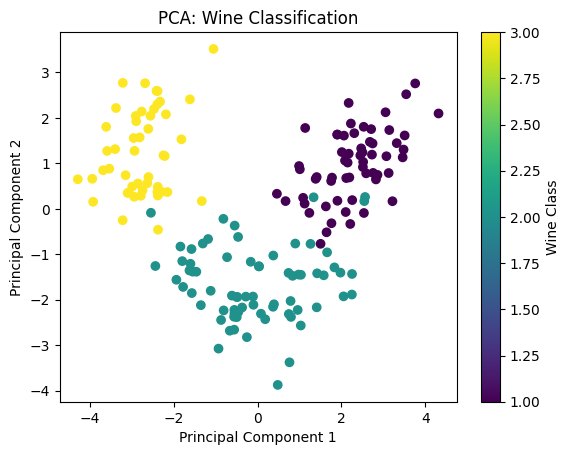

In [ ]:

plt.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=y,
    cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Wine Classification")
plt.colorbar(label="Wine Class")
plt.show()


In [ ]:

print("Original shape:", X.shape)
print("Reduced shape:", X_reduced.shape)
print("Explained variance:", pca.explained_variance_ratio_)
print("Total variance retained:",
      pca.explained_variance_ratio_.sum())


Original shape: (178, 13)
Reduced shape: (178, 2)
Explained variance: [0.36198848 0.1920749 ]
Total variance retained: 0.5540633835693527
